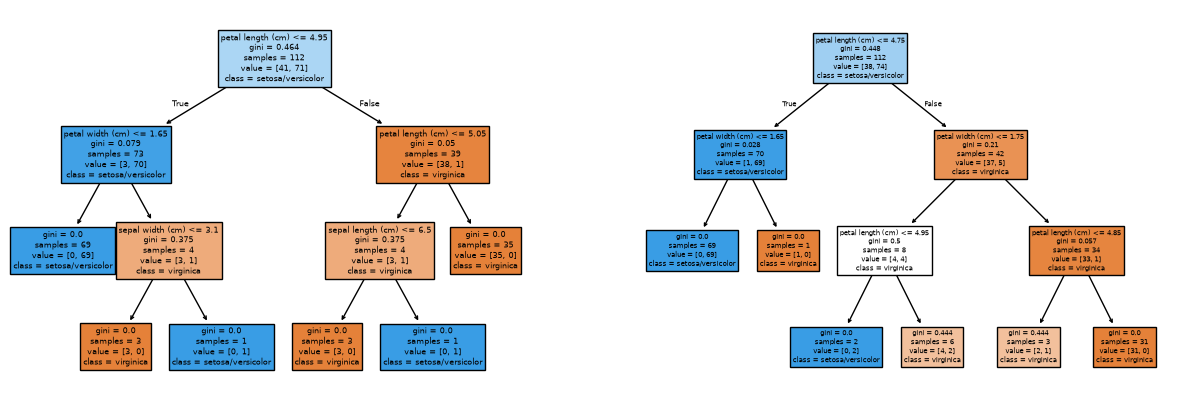

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris


dataset = load_iris()

df = pd.DataFrame(dataset.data, columns=dataset.feature_names)  # type: ignore
X = df[dataset.feature_names]  # type: ignore
y = df["target"] = dataset.target != 2  # type: ignore

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X, y, random_state=0  # type: ignore
)

clf1 = DecisionTreeClassifier(max_depth=3)
clf1.fit(X_train1, y_train1)

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, random_state=42
)

clf2 = DecisionTreeClassifier(max_depth=3)
clf2.fit(X_train2, y_train2)

fn = ["sepal length (cm)", "sepal width (cm)",
      "petal length (cm)", "petal width (cm)"]
cn = ["virginica", "setosa/versicolor"]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5), dpi=100)
tree.plot_tree(clf1, feature_names=fn, class_names=cn, filled=True, ax=axes[0])
tree.plot_tree(clf2, feature_names=fn, class_names=cn, filled=True, ax=axes[1])
plt.show()

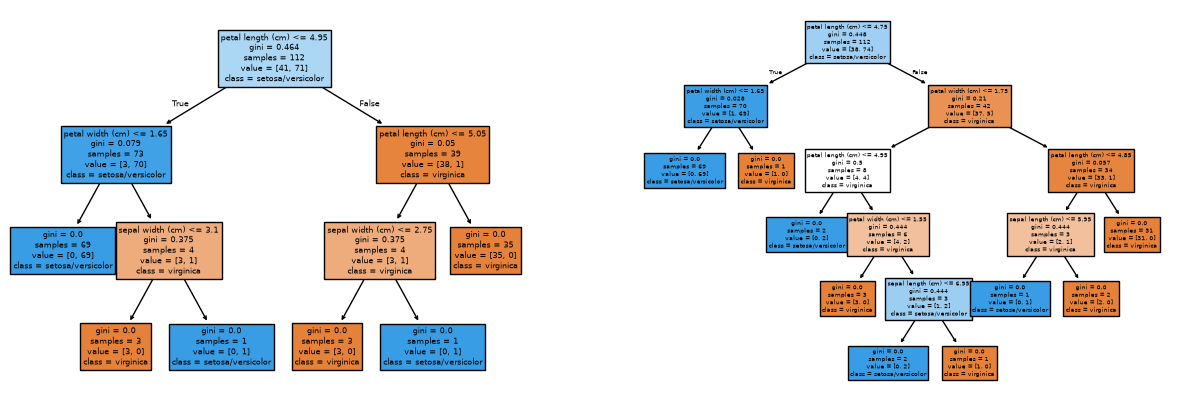

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris


dataset = load_iris()

df = pd.DataFrame(dataset.data, columns=dataset.feature_names)  # type: ignore
X = df[dataset.feature_names]  # type: ignore
y = df["target"] = dataset.target != 2  # type: ignore

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X, y, random_state=0  # type: ignore
)

clf1 = DecisionTreeClassifier(max_depth=10)
clf1.fit(X_train1, y_train1)

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, random_state=42
)

clf2 = DecisionTreeClassifier(max_depth=10)
clf2.fit(X_train2, y_train2)

fn = ["sepal length (cm)", "sepal width (cm)",
      "petal length (cm)", "petal width (cm)"]
cn = ["virginica", "setosa/versicolor"]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5), dpi=100)
tree.plot_tree(clf1, feature_names=fn, class_names=cn, filled=True, ax=axes[0])
tree.plot_tree(clf2, feature_names=fn, class_names=cn, filled=True, ax=axes[1])
plt.show()

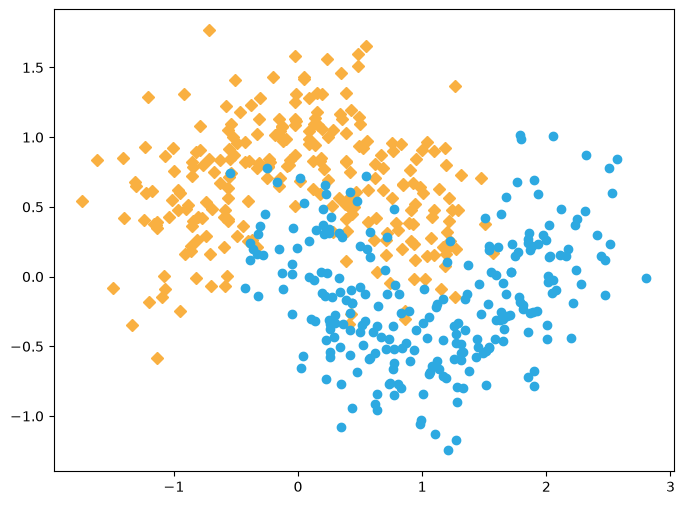

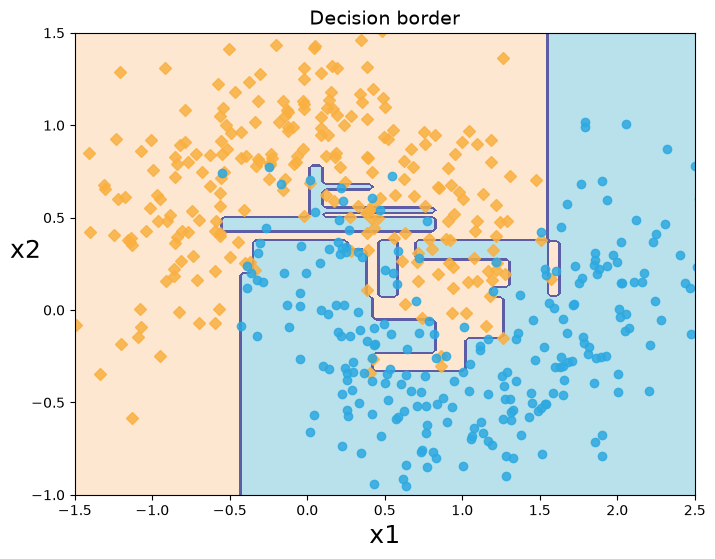

In [9]:
import numpy as np
from sklearn.datasets import make_moons
from matplotlib.colors import ListedColormap


def plot_decision_boundary(
    clf, x, y, axes=[-1.5, 2.5, -1, 1.5], alpha=0.85, contour=True, bolded=False
):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)

    x_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(x_new).reshape(x1.shape)
    custom_cmap = ListedColormap(["#FEE7D0", "#bea6ff", "#B8E1EC"])
    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)

    if contour:
        custom_cmap2 = ListedColormap(["#FEE7D0", "#5D5DA6", "#B8E1EC"])

        if bolded:
            custom_cmap2 = ListedColormap(["#FEE7D0", "#5D5DA6", "#000000"])
        plt.contourf(x1, x2, y_pred, cmap=custom_cmap2)
    plt.plot(x[:, 0][y == 0], x[:, 1][y == 0], "D", c="#F9B041", alpha=alpha)
    plt.plot(x[:, 0][y == 1], x[:, 1][y == 1], "o", c="#2DA9E1", alpha=alpha)
    plt.axis(axes)
    plt.xlabel(r"x1", fontsize=18)
    plt.ylabel(r"x2", fontsize=18, rotation=0)


x, y = make_moons(n_samples=500, noise=0.30, random_state=42)

plt.figure(figsize=(8, 6))
plt.plot(x[:, 0][y == 0], x[:, 1][y == 0], "D", c="#F9B041")
plt.plot(x[:, 0][y == 1], x[:, 1][y == 1], "o", c="#2DA9E1")
plt.show()

x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=42)

plt.figure(figsize=(8, 6))
clf = DecisionTreeClassifier(max_depth=20, random_state=42)
clf.fit(x_train, y_train)
plot_decision_boundary(clf, x, y)
plt.title("Decision border", fontsize=14)
plt.show()